<a href="https://colab.research.google.com/github/ananthika123/AI-ML-ICT-Academy/blob/main/NLP_Classification_DonorsChoose_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install and import libraries


In [16]:
%pip -q install nltk gensim scikit-learn seaborn tensorflow

In [36]:
import  re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
)
from sklearn.utils.class_weight import compute_class_weight

import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Load the CSV


In [18]:
df = pd.read_csv("/content/drive/MyDrive/ICT AI ML/archive (9)/Preprocessed_DonorsChoose_dataset.csv")
print("Shape:", df.shape)
display(df.head())
display(df.info())

Shape: (109248, 14)


,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109248 entries, 0 to 109247
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   id                                            109248 non-null  object 
 1   teacher_prefix                                109248 non-null  object 
 2   school_state                                  109248 non-null  object 
 3   project_grade_category                        109248 non-null  object 
 4   project_subject_categories                    109248 non-null  object 
 5   project_subject_subcategories                 109248 non-null  object 
 6   teacher_number_of_previously_posted_projects  109248 non-null  int64  
 7   project_is_approved                           109248 non-null  int64  
 8   price                                         109248 non-null  float64
 9   quantity                                      10

None

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Columns:
['id', 'teacher_prefix', 'school_state', 'project_grade_category', 'project_subject_categories', 'project_subject_subcategories', 'teacher_number_of_previously_posted_projects', 'project_is_approved', 'price', 'quantity', 'cleaned_titles', 'cleaned_essays', 'cleaned_summary', 'isdigit_summary']

Missing values (top 25):


,missing_count
cleaned_titles,43
id,0
school_state,0
project_grade_category,0
project_subject_categories,0
teacher_prefix,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
price,0
project_is_approved,0


Detected target: project_is_approved

Target counts:


,count
project_is_approved,
1,92706
0,16542


,percent
project_is_approved,
1,84.86
0,15.14


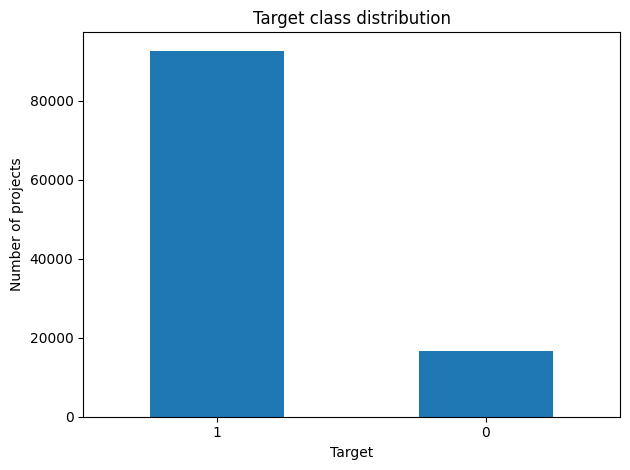

In [20]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values (top 25):")
display(df.isna().sum().sort_values(ascending=False).head(25).to_frame("missing_count"))

target_candidates = [
    "project_is_approved", "funded", "is_funded", "funding_status",
    "approved", "target", "label"
]
TARGET_COL = next((c for c in target_candidates if c in df.columns), None)
print("Detected target:", TARGET_COL)

if TARGET_COL is None:
    raise ValueError(
        "Target column not detected. Inspect df.columns and set TARGET_COL manually. "
        "If this file has no funding/approval label, use a different labeled CSV or define "
        "a justified alternative target."
    )

print("\nTarget counts:")
display(df[TARGET_COL].value_counts(dropna=False).to_frame("count"))
display((df[TARGET_COL].value_counts(normalize=True, dropna=False)*100).round(2).to_frame("percent"))

ax = df[TARGET_COL].value_counts().plot(kind="bar", rot=0, title="Target class distribution")
ax.set_xlabel("Target")
ax.set_ylabel("Number of projects")
plt.tight_layout()
plt.show()

Select and combine textual fields



In [21]:
text_candidates = [
    "project_title", "title", "short_description", "project_short_description",
    "project_essay_1", "project_essay_2", "project_essay_3", "project_essay_4",
    "project_description", "description", "essay"
]
TEXT_COLS = [c for c in text_candidates if c in df.columns]
print("Detected text columns:", TEXT_COLS)

if not TEXT_COLS:
    raise ValueError("No known text columns detected. Set TEXT_COLS manually from df.columns.")

# Remove rows with missing target; normalize target to 0/1 if needed.
data = df.dropna(subset=[TARGET_COL]).copy()
y_raw = data[TARGET_COL]

# Convert common binary text labels or numeric targets into a binary encoded target.
if y_raw.nunique() != 2:
    raise ValueError(f"Expected a binary target, found {y_raw.nunique()} classes: {y_raw.unique()[:20]}")

if set(pd.Series(y_raw.dropna().unique()).astype(str)) <= {"0", "1", "0.0", "1.0"}:
    y = y_raw.astype(int).to_numpy()
else:
    le = LabelEncoder()
    y = le.fit_transform(y_raw.astype(str))
    print("Target mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

data["combined_text_raw"] = data[TEXT_COLS].fillna("").astype(str).agg(" ".join, axis=1)
data["combined_text_raw"] = data["combined_text_raw"].str.strip()
data = data[data["combined_text_raw"].str.len() > 0].copy()
# Keep y aligned after filtering empty text rows.
if set(pd.Series(y_raw.dropna().unique()).astype(str)) <= {"0", "1", "0.0", "1.0"}:
    y = data[TARGET_COL].astype(int).to_numpy()
else:
    y = le.transform(data[TARGET_COL].astype(str))

print("Usable rows:", len(data))
print("Target counts after cleaning:", pd.Series(y).value_counts().to_dict())
display(data[TEXT_COLS + [TARGET_COL]].head(3))

Detected text columns: ['cleaned_titles', 'cleaned_essays', 'cleaned_summary']
Usable rows: 109248
Target counts after cleaning: {1: 92706, 0: 16542}


,cleaned_titles,cleaned_essays,cleaned_summary,project_is_approved
0,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,1
2,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0


NLP preprocessing



In [22]:
STOP_WORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)          # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)             # numbers
    text = re.sub(r"[^a-z\s]", " ", text)        # punctuation/special characters
    tokens = re.findall(r"[a-z]+", text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in STOP_WORDS and len(t) > 1]
    return " ".join(tokens)

data["clean_text"] = data["combined_text_raw"].map(clean_text)
data = data[data["clean_text"].str.strip().ne("")].copy()
# Re-align labels after removing empty documents.
if set(pd.Series(df[TARGET_COL].dropna().unique()).astype(str)) <= {"0", "1", "0.0", "1.0"}:
    y = data[TARGET_COL].astype(int).to_numpy()
else:
    y = le.transform(data[TARGET_COL].astype(str))

print("Rows after text cleaning:", len(data))
print(data["clean_text"].head(2).tolist())
print("Average token count:", data["clean_text"].str.split().str.len().mean())

Rows after text cleaning: 109248
['educational support english learner home student english learner working english second third language melting pot refugee immigrant native born american bringing gift language school language represented english learner program student every level mastery also country represented family within school student brings wealth knowledge experience u open eye new culture belief respect limit language limit world ludwig wittgenstein english learner strong support system home begs resource many time parent learning read speak english along side child sometimes creates barrier parent able help child learn phonetics letter recognition reading skill providing dvd player student able continue mastery english language even one home able assist family student within level proficiency status offered part program educational video specially chosen english learner teacher sent home regularly watch video help child develop early reading skill parent access dvd player 

Train / validation / test split


In [23]:
X_text = data["clean_text"].to_numpy()
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print("Train/validation/test:", len(y_train), len(y_val), len(y_test))
print("Train class ratio:", pd.Series(y_train).value_counts(normalize=True).round(3).to_dict())

Train/validation/test: 76473 16387 16388
Train class ratio: {1: 0.849, 0: 0.151}


TF-IDF features



In [24]:
MAX_TFIDF_FEATURES = 50000
tfidf = TfidfVectorizer(
    max_features=MAX_TFIDF_FEATURES,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    dtype=np.float32
)
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("TF-IDF shapes:", X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)

TF-IDF shapes: (76473, 50000) (16387, 50000) (16388, 50000)


Classical models + cross-validation tuning


In [25]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, class_weight="balanced", solver="liblinear"),
    param_grid={"C": [0.1, 1.0, 3.0]},
    scoring="f1_macro", cv=cv, n_jobs=-1, verbose=1
)
lr_grid.fit(X_train_tfidf, y_train)
best_lr = lr_grid.best_estimator_
print("Best Logistic Regression params:", lr_grid.best_params_)
print("Best CV macro F1:", round(lr_grid.best_score_, 4))

svm_grid = GridSearchCV(
    LinearSVC(class_weight="balanced"),
    param_grid={"C": [0.1, 1.0, 3.0]},
    scoring="f1_macro", cv=cv, n_jobs=-1, verbose=1
)
svm_grid.fit(X_train_tfidf, y_train)
best_svm = svm_grid.best_estimator_
print("Best Linear SVM params:", svm_grid.best_params_)
print("Best CV macro F1:", round(svm_grid.best_score_, 4))

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Logistic Regression params: {'C': 1.0}
Best CV macro F1: 0.606
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Linear SVM params: {'C': 0.1}
Best CV macro F1: 0.6056


Word2Vec document vectors



In [26]:
from gensim.models import Word2Vec

tokenized_train = [doc.split() for doc in X_train_text]
tokenized_val = [doc.split() for doc in X_val_text]
tokenized_test = [doc.split() for doc in X_test_text]

W2V_DIM = 100
w2v = Word2Vec(
    sentences=tokenized_train,
    vector_size=W2V_DIM,
    window=5,
    min_count=2,
    workers=2,
    sg=0,             # 0 = CBOW, 1 = skip-gram
    epochs=10,
    seed=SEED
)

def document_vector(tokens, model, dim=W2V_DIM):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(dim, dtype=np.float32)
    return np.mean(vectors, axis=0).astype(np.float32)

X_train_w2v = np.vstack([document_vector(t, w2v) for t in tokenized_train])
X_val_w2v = np.vstack([document_vector(t, w2v) for t in tokenized_val])
X_test_w2v = np.vstack([document_vector(t, w2v) for t in tokenized_test])
print("Word2Vec shapes:", X_train_w2v.shape, X_val_w2v.shape, X_test_w2v.shape)

Word2Vec shapes: (76473, 100) (16387, 100) (16388, 100)


## 10. Classical model on Word2Vec vectors (optional comparison)

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

w2v_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
w2v_lr.fit(X_train_w2v, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [28]:
# Limit the dense neural network input size for memory efficiency.
DL_TFIDF_FEATURES = min(5000, X_train_tfidf.shape[1])
dl_tfidf = TfidfVectorizer(
    max_features=DL_TFIDF_FEATURES,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    dtype=np.float32
)
X_train_tfidf_dl = dl_tfidf.fit_transform(X_train_text).toarray().astype(np.float32)
X_val_tfidf_dl = dl_tfidf.transform(X_val_text).toarray().astype(np.float32)
X_test_tfidf_dl = dl_tfidf.transform(X_test_text).toarray().astype(np.float32)

tfidf_input = keras.Input(shape=(X_train_tfidf_dl.shape[1],), name="tfidf_input")
x1 = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4))(tfidf_input)
x1 = layers.BatchNormalization()(x1)
x1 = layers.Dropout(0.4)(x1)
x1 = layers.Dense(64, activation="relu")(x1)

w2v_input = keras.Input(shape=(W2V_DIM,), name="word2vec_input")
x2 = layers.Dense(64, activation="relu")(w2v_input)
x2 = layers.Dropout(0.25)(x2)

merged = layers.Concatenate()([x1, x2])
merged = layers.Dense(64, activation="relu")(merged)
merged = layers.Dropout(0.3)(merged)
output = layers.Dense(1, activation="sigmoid", name="funding_probability")(merged)

dl_model = keras.Model(inputs=[tfidf_input, w2v_input], outputs=output)
dl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)
dl_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tfidf_input         │ (None, 5000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  1,280,256 │ tfidf_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word2vec_input      │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      6,464 │ word2vec_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     16,448 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ funding_probability │ (None, 1)         │         65 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,312,513 (5.01 MB)

 Trainable params: 1,312,001 (5.00 MB)

 Non-trainable params: 512 (2.00 KB)

### Train the deep learning model


Epoch 1/15
598/598 ━━━━━━━━━━━━━━━━━━━━ 29s 43ms/step - accuracy: 0.6426 - auc: 0.6846 - loss: 0.7007 - precision: 0.9057 - recall: 0.6461 - val_accuracy: 0.6005 - val_auc: 0.7159 - val_loss: 0.7467 - val_precision: 0.9234 - val_recall: 0.5771 - learning_rate: 0.0010
Epoch 2/15
598/598 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.7037 - auc: 0.7643 - loss: 0.6650 - precision: 0.9272 - recall: 0.7062 - val_accuracy: 0.6978 - val_auc: 0.7027 - val_loss: 0.6943 - val_precision: 0.9087 - val_recall: 0.7158 - learning_rate: 0.0010
Epoch 3/15
598/598 ━━━━━━━━━━━━━━━━━━━━ 25s 42ms/step - accuracy: 0.7548 - auc: 0.8388 - loss: 0.6257 - precision: 0.9479 - recall: 0.7525 - val_accuracy: 0.7434 - val_auc: 0.6742 - val_loss: 0.6844 - val_precision: 0.8906 - val_recall: 0.7953 - learning_rate: 0.0010
Epoch 4/15
598/598 ━━━━━━━━━━━━━━━━━━━━ 43s 45ms/step - accuracy: 0.8320 - auc: 0.9174 - loss: 0.5463 - precision: 0.9678 - recall: 0.8296 - val_accuracy: 0.7742 - val_auc: 0.6671 - val_loss: 0.74

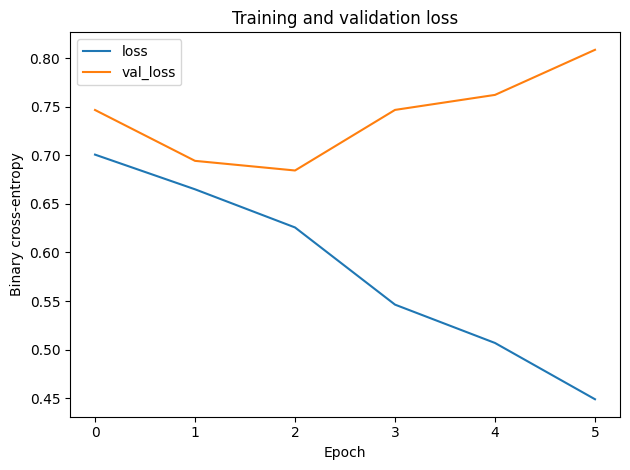

In [29]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
]

history = dl_model.fit(
    [X_train_tfidf_dl, X_train_w2v], y_train,
    validation_data=([X_val_tfidf_dl, X_val_w2v], y_val),
    epochs=15,
    batch_size=128,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

pd.DataFrame(history.history)[["loss", "val_loss"]].plot(title="Training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.tight_layout()
plt.show()

Evaluation helpers and final test metrics



In [30]:
results = []

def evaluate_model(name, y_true, y_pred, y_score=None):
    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_score is not None:
        row["roc_auc"] = roc_auc_score(y_true, y_score)
        row["average_precision"] = average_precision_score(y_true, y_score)
    else:
        row["roc_auc"] = np.nan
        row["average_precision"] = np.nan
    results.append(row)
    print("\n", name)
    print(classification_report(y_true, y_pred, zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))
    return row

# Logistic Regression
lr_pred = best_lr.predict(X_test_tfidf)
lr_score = best_lr.predict_proba(X_test_tfidf)[:, 1]
evaluate_model("TF-IDF + Logistic Regression", y_test, lr_pred, lr_score)

# Linear SVM: decision_function gives ranking scores suitable for ROC-AUC.
svm_pred = best_svm.predict(X_test_tfidf)
svm_score = best_svm.decision_function(X_test_tfidf)
evaluate_model("TF-IDF + Linear SVM", y_test, svm_pred, svm_score)

# Word2Vec + Logistic Regression
w2v_score = w2v_lr.predict_proba(X_test_w2v)[:, 1]
w2v_pred = (w2v_score >= 0.5).astype(int)
evaluate_model("Word2Vec average + Logistic Regression", y_test, w2v_pred, w2v_score)

# Two-input Keras model
dl_score = dl_model.predict([X_test_tfidf_dl, X_test_w2v], verbose=0).ravel()
dl_pred = (dl_score >= 0.5).astype(int)
evaluate_model("Functional API: TF-IDF + Word2Vec", y_test, dl_pred, dl_score)

results_df = pd.DataFrame(results).sort_values("f1", ascending=False)
display(results_df.round(4))


 TF-IDF + Logistic Regression
              precision    recall  f1-score   support

           0       0.30      0.55      0.39      2482
           1       0.91      0.77      0.83     13906

    accuracy                           0.74     16388
   macro avg       0.60      0.66      0.61     16388
weighted avg       0.81      0.74      0.76     16388

Confusion matrix:
 [[ 1370  1112]
 [ 3223 10683]]

 TF-IDF + Linear SVM
              precision    recall  f1-score   support

           0       0.30      0.56      0.39      2482
           1       0.91      0.76      0.83     13906

    accuracy                           0.73     16388
   macro avg       0.60      0.66      0.61     16388
weighted avg       0.81      0.73      0.76     16388

Confusion matrix:
 [[ 1382  1100]
 [ 3273 10633]]

 Word2Vec average + Logistic Regression
              precision    recall  f1-score   support

           0       0.25      0.67      0.37      2482
           1       0.92      0.65      0.76

,model,accuracy,precision,recall,f1,roc_auc,average_precision
3,Functional API: TF-IDF + Word2Vec,0.7514,0.8938,0.8024,0.8456,0.6876,0.9159
0,TF-IDF + Logistic Regression,0.7355,0.9057,0.7682,0.8313,0.7240,0.9259
1,TF-IDF + Linear SVM,0.7332,0.9062,0.7646,0.8294,0.7248,0.9260
2,Word2Vec average + Logistic Regression,0.6494,0.9163,0.6458,0.7577,0.7106,0.9197


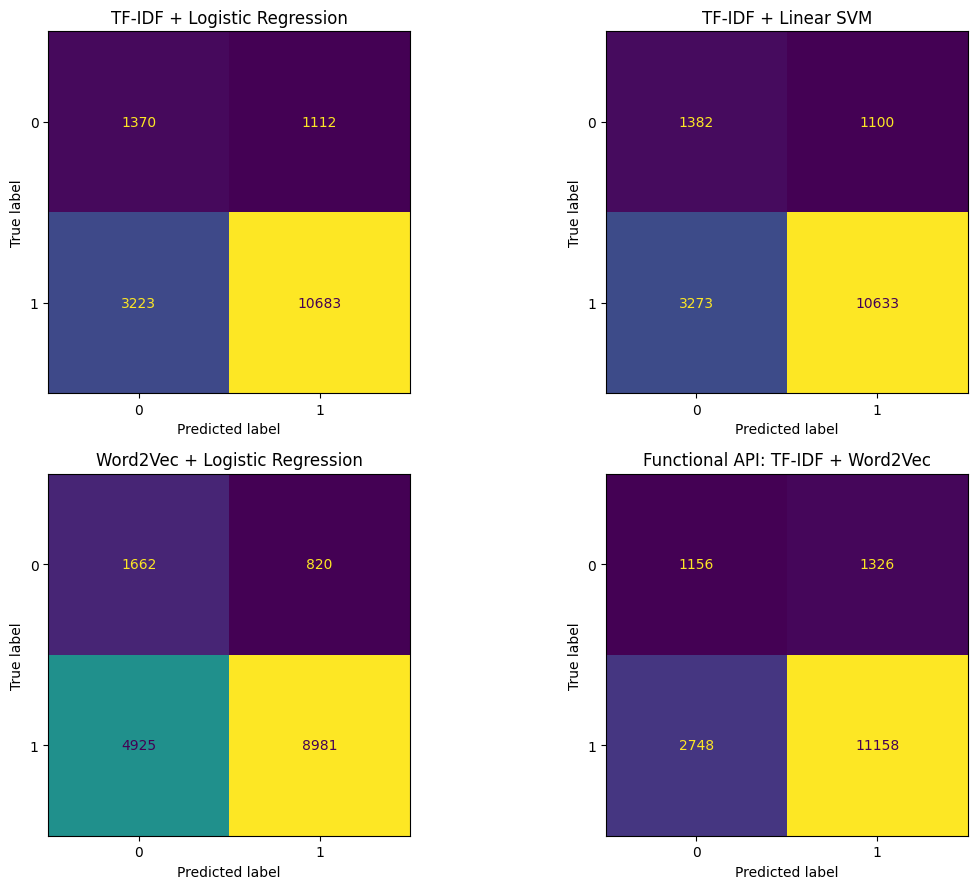

In [31]:
# Confusion matrices for each model
predictions = {
    "TF-IDF + Logistic Regression": lr_pred,
    "TF-IDF + Linear SVM": svm_pred,
    "Word2Vec + Logistic Regression": w2v_pred,
    "Functional API: TF-IDF + Word2Vec": dl_pred,
}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

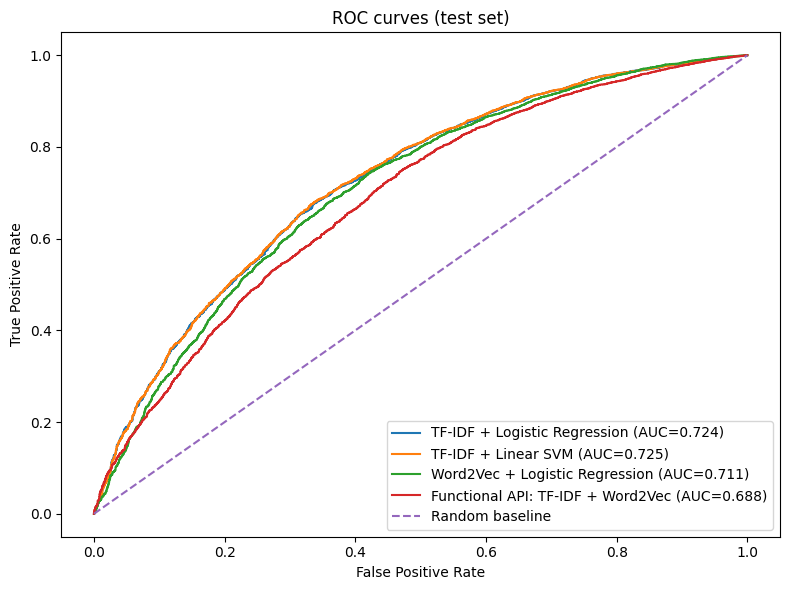

In [32]:
# ROC curves
score_map = {
    "TF-IDF + Logistic Regression": lr_score,
    "TF-IDF + Linear SVM": svm_score,
    "Word2Vec + Logistic Regression": w2v_score,
    "Functional API: TF-IDF + Word2Vec": dl_score,
}
plt.figure(figsize=(8, 6))
for name, score in score_map.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    auc_value = roc_auc_score(y_test, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves (test set)")
plt.legend()
plt.tight_layout()
plt.show()

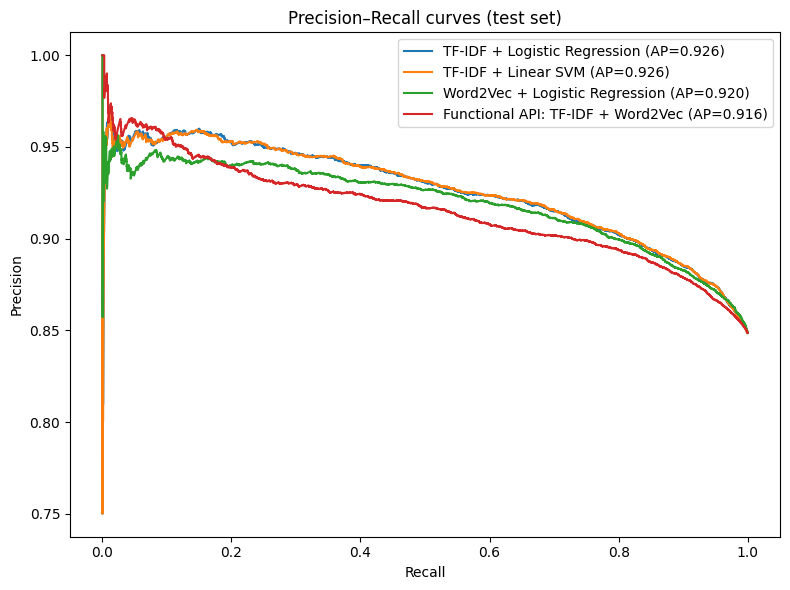

In [33]:
# Precision-recall curves are useful for imbalanced classes.
plt.figure(figsize=(8, 6))
for name, score in score_map.items():
    precision, recall, _ = precision_recall_curve(y_test, score)
    ap = average_precision_score(y_test, score)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall curves (test set)")
plt.legend()
plt.tight_layout()
plt.show()

Save artifacts



In [34]:
import joblib

joblib.dump(tfidf, "tfidf_vectorizer.joblib")
joblib.dump(best_lr, "logistic_regression_tfidf.joblib")
joblib.dump(best_svm, "linear_svm_tfidf.joblib")
joblib.dump(w2v, "custom_word2vec.model")
dl_model.save("donorschoose_functional_api.keras")
print("Saved model artifacts in the current directory.")

Saved model artifacts in the current directory.
